# 高维数据与维度灾难
所有实验使用真实白血病数据。先填写预测，再运行。

In [8]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
HERE=Path.cwd().resolve()
REPO=next((p for p in [HERE,*HERE.parents] if (p/"assignments/hw03/resources/scripts/experiments.py").exists()),None)
if REPO is None: raise RuntimeError("请在课程仓库内运行HW03 Notebook")
BASE=REPO/"assignments/hw03/resources"
sys.path.insert(0,str(BASE/"scripts"))
import experiments as lab
OUT=HERE/"student-results"
OUT.mkdir(exist_ok=True)

## T1 读取真实数据

In [9]:
df,X,names=lab.load_real()
print("n,p",X.shape,"p/n",X.shape[1]/X.shape[0])
display(df.groupby(["original_split","diagnosis"]).size().rename("n").to_frame())
display(df.iloc[:3,:6])

n,p (72, 7129) p/n 99.01388888888889


n
original_split diagnosis    
test           ALL        20
               AML        14
train          ALL        27
               AML        11

,sample_id,original_split,diagnosis,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at
0,G001,train,ALL,-214,-153,-58
1,G002,train,ALL,-139,-73,-1
2,G003,train,ALL,-76,-49,-307


## T2 实验A 距离
先写预测。诊断只在图中事后着色。

,42,7,2026
0,X51730_at,M60052_at,U26727_at
1,U13616_at,HG2600-HT2696_at,M34516_r_at
2,X97261_at,X04741_at,U59831_rna1_s_at


,seed,p,mean,sd,cv,near_median,far_median,gap_median,r_median,zero_nearest
0,42,2,1.268799,1.564125,1.232761,0.067518,7.903008,7.860022,115.451967,0
1,42,3,1.810146,1.675672,0.925711,0.234539,8.763866,8.482727,35.998344,0
2,42,10,4.215053,1.585882,0.376243,1.797615,9.655803,7.559482,4.318717,0
3,42,100,13.916946,3.022502,0.217181,9.669579,21.461561,12.011417,1.199352,0
4,42,1000,44.181567,8.726863,0.197523,33.067257,66.515369,34.236792,1.048856,0
5,42,7129,118.196488,22.099935,0.186976,87.931134,174.900278,87.138000,0.966904,0


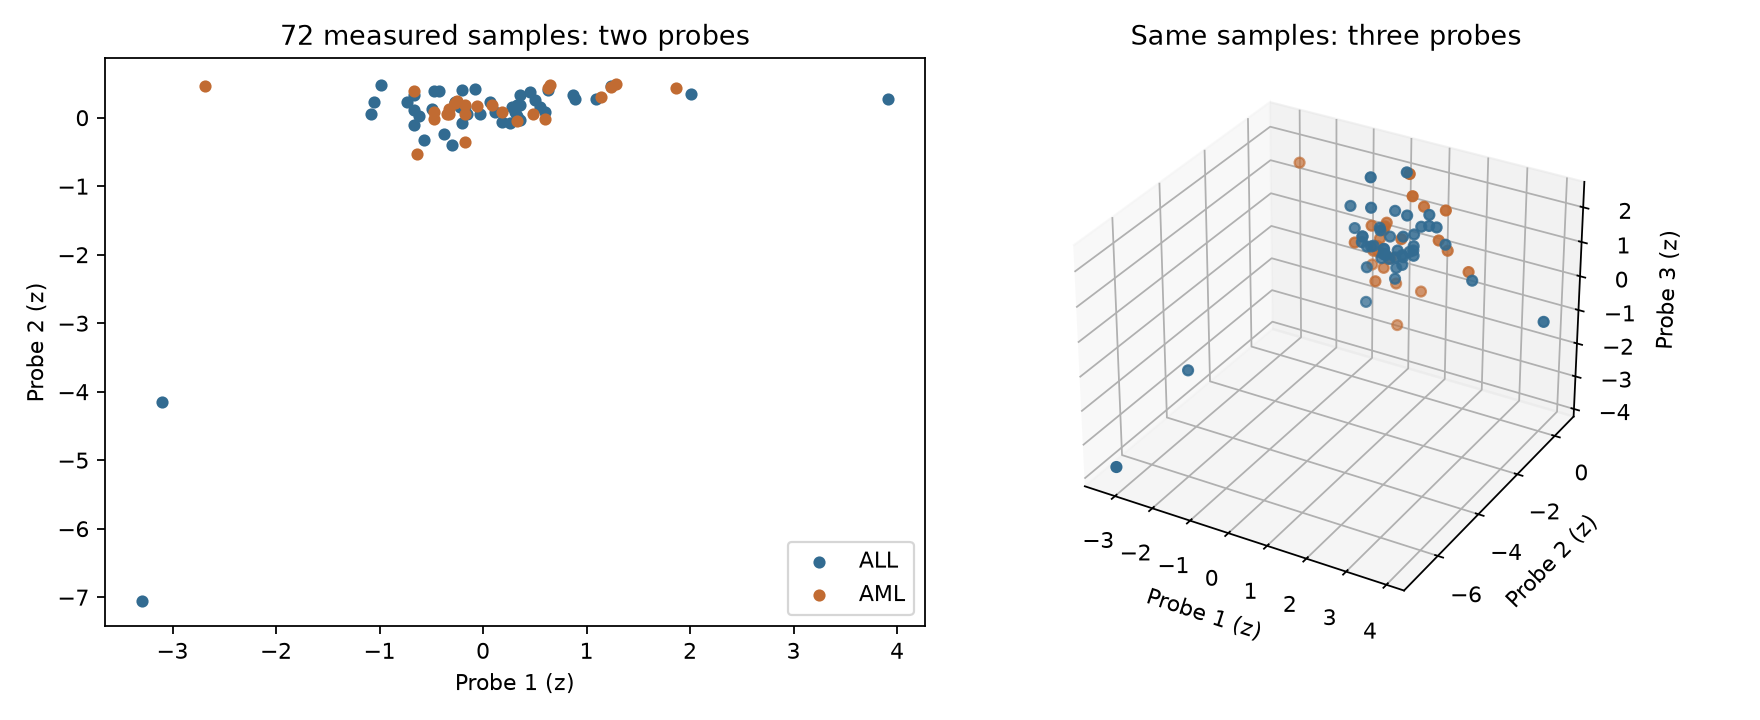

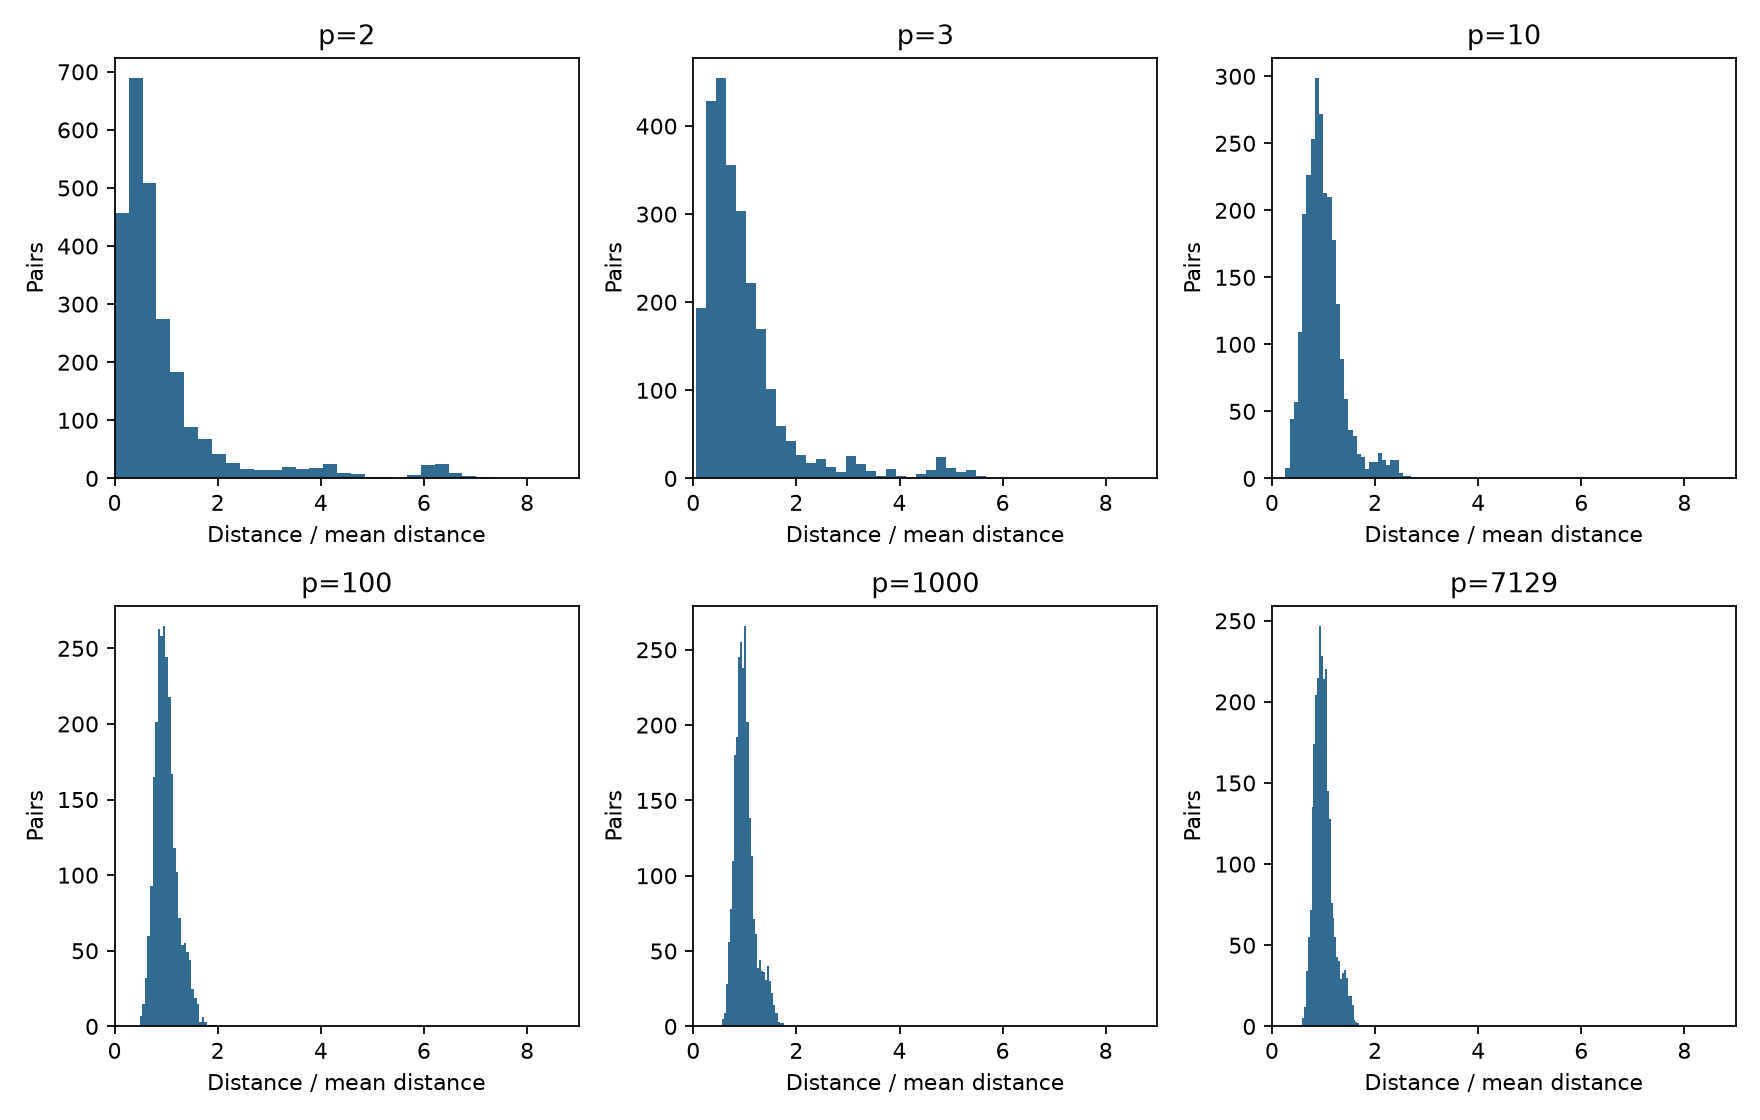

In [10]:
a=lab.experiment_a(OUT)
display(pd.read_csv(OUT/"A-probe-orders.csv").head(3))
display(a[a.seed.eq(42)])
display(Image(filename=str(OUT/"A-scatter-2D-3D.png")))
display(Image(filename=str(OUT/"A-distance-distributions.png")))

## T3 近远邻与选列

In [11]:
near=pd.read_csv(OUT/"A-neighbors-seed42.csv")
display(near[near.sample_id.eq("G001") & near.p.isin([2,7129])])
display(a[["seed","p","cv","r_median","gap_median"]])

,sample_id,p,near,far,R
0,G001,2,0.049192,7.954082,160.695864
360,G001,7129,93.695760,156.146171,0.666523


,seed,p,cv,r_median,gap_median
0,42,2,1.232761,115.451967,7.860022
1,42,3,0.925711,35.998344,8.482727
2,42,10,0.376243,4.318717,7.559482
3,42,100,0.217181,1.199352,12.011417
4,42,1000,0.197523,1.048856,34.236792
5,42,7129,0.186976,0.966904,87.138000
6,7,2,0.614496,23.676032,4.234162
7,7,3,0.539419,10.198094,4.667459
8,7,10,0.301309,2.400987,5.317424
9,7,100,0.214420,1.286433,13.079189


## T4 实验B 先看训练
先记录训练分数能支持什么。

In [12]:
b,cv=lab.experiment_b(OUT)
display(b[["p","train_ba"]])

,p,train_ba
0,2,1.0
1,10,1.0
2,100,1.0
3,1000,1.0
4,7129,1.0


记录判断后再看测试。

,p,train_ba,test_ba,ALL_correct,AML_correct
0,2,1.0,0.496429,17,2
1,10,1.0,0.578571,16,5
2,100,1.0,0.653571,19,5
3,1000,1.0,0.725000,19,7
4,7129,1.0,0.760714,19,8


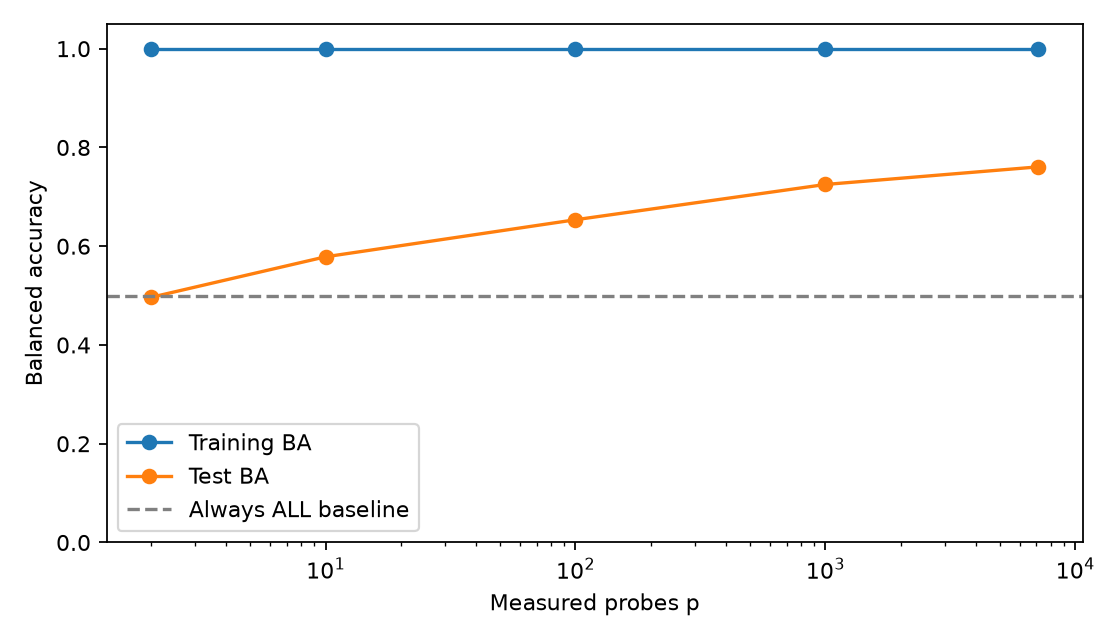

恒预测ALL的BA基线0.5


In [13]:
display(b)
display(Image(filename=str(OUT/"B-generalization.png")))
print("恒预测ALL的BA基线0.5")

## T5 退出卡
在工作单完成理论计算、流程修复与结论。

## H1 验证与筛选稳定性

In [14]:
display(cv.groupby("method").validation_ba.agg(["mean","min","max","std"]))
display(cv)
stability=pd.read_csv(OUT/"B-selection-stability.csv")
display(stability.jaccard.agg(["median","min","max"]))
import importlib.metadata
print({n:importlib.metadata.version(n) for n in ["numpy","pandas","scipy","scikit-learn","matplotlib"]})

,mean,min,max,std
method,,,,
all7129,0.844136,0.694444,1.0,0.106858
select20,0.885802,0.750000,1.0,0.083269


,repeat,fold,method,train_n,validation_n,train_ba,validation_ba
0,1,1,all7129,25,13,1.0,0.819444
1,1,1,select20,25,13,1.0,0.875000
2,1,2,all7129,25,13,1.0,0.875000
3,1,2,select20,25,13,1.0,0.944444
4,1,3,all7129,26,12,1.0,0.833333
5,1,3,select20,26,12,1.0,1.000000
6,2,1,all7129,25,13,1.0,0.750000
7,2,1,select20,25,13,1.0,0.750000
8,2,2,all7129,25,13,1.0,0.875000
9,2,2,select20,25,13,1.0,0.819444


median    0.270161
min       0.142857
max       0.428571
Name: jaccard, dtype: float64

{'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.0'}


## 我的解释
填写主张、距离证据、泛化证据、推理和边界，记录代码或参数改动。


### 1. 主张

我不赞同“特征越多，模型一定越好”。增加探针既可能引入有效的疾病相关信号，也可能增加噪声或冗余信息。模型表现取决于特征内容、样本量、模型及验证方式，不能只根据特征数量判断。本次实验中，更多探针改善了当前测试集上的表现，但不足以证明在其他数据或新患者中也一定更好。

### 2. 距离证据

在实验 A 中，固定72份样本，逐探针进行 z-score 标准化，并使用 seed=42 的嵌套探针子集：

- 当 p=2 时，平均距离为1.268799，距离 CV 为1.232761，R 中位数为115.451967。
- 当 p=7129 时，平均距离为118.196488，距离 CV 为0.186976，R 中位数为0.966904。

这些结果表明，探针数增加后，平均欧氏距离变大，但距离相对于均值的离散程度下降，最近邻与最远邻的相对差异也缩小。这与绝对差变大并不矛盾：全体样本的近远邻绝对距离差中位数由7.860022增加至87.138000，因此不能把距离集中理解为所有距离都趋于相等或绝对差趋于零。

### 3. 泛化证据

实验 B 使用原始38份训练样本和34份测试样本，采用 StandardScaler→1近邻流程，标准化只在训练部分拟合。

五种探针数量下的训练 BA 均为1.000，而测试 BA 随 p=2、10、100、1000、7129 分别为0.496429、0.578571、0.653571、0.725000、0.760714。全部7129个探针时，ALL 正确19/20，AML 正确8/14，因此：

BA = (19/20 + 8/14) / 2 = 0.760714。

恒预测 ALL 的 BA 基线为0.500。这说明更多探针在本次固定划分中改善了分类表现，但训练满分本身不能证明泛化良好。

在原训练集内进行3折×3重复验证时，全部探针的验证 BA 均值为0.844136，范围为0.694444–1.000000；每个训练折内筛选20个探针的均值为0.885802，范围为0.750000–1.000000。筛选平均表现更高，但并非每折都改善。筛选集合的 Jaccard 中位数为0.270161，范围为0.142857–0.428571，说明所选探针列表对训练样本划分较敏感。

### 4. 推理

1近邻在训练集上预测时，通常会将样本自身作为距离为零的最近邻，所以训练满分主要体现了训练记忆，低维时也可能出现。评价模型需要查看未参与拟合的验证或测试样本。

高维距离的相对差异缩小，可能削弱距离对样本关系的区分能力，但不能由此断定分类表现必然下降。本次测试 BA 随探针数量增加而提高，可能是因为新增探针累积了疾病相关信号。同时，每次增加探针既改变了维度，也改变了特征内容，不能把性能变化完全归因于维度。

折内筛选减少了输入特征数量，平均验证表现有所提高，但列表不稳定、部分折表现下降，说明减少特征也不是必然更好的方案，需要结合无泄漏的验证结果判断。

### 5. 边界

上述结论仅适用于当前表达数据、标准化方式、欧氏距离、1近邻模型和指定划分，不能推广为所有高维数据的规律。九个验证折反复使用同一批训练样本，存在重叠，不能视为九项独立研究。

数据缺少患者重复映射、中心和批次信息，因此无法充分判断样本独立性及批次混杂；7129个探针也不等于7129个不同基因或独立信息。当前历史测试集表现不等于新患者的临床性能，更不能证明因果关系。后续应锁定分析流程，在患者独立、具有代表性的外部队列中验证，并报告性能的不确定性。

### 6. 代码或参数改动

未修改课程提供的 experiments.py、原始表达数据、诊断标签及实验模型参数。实验 A 使用随机种子42、7、2026；实验 B 的探针列序和训练内重复分层交叉验证使用随机种子42；筛选数量固定为20，没有根据测试集表现反复选择探针数量。

Notebook 文件名修改为38720260158045-陈乐颜-high-dimension-lab.ipynb，并将结果统一保存到 git-practice-classroom\submissions\hw03，避免运行产物混入个人提交目录。这些改动不改变实验计算方法。